In [12]:
import pandas as pd
import numpy as np

# 1. 데이터 불러오기
df = pd.read_csv(
    "data/clean_rentals.csv",
    parse_dates=["rent_time", "return_time"]
)

# 2. 대여 시간 계산 (분)
df["duration_min"] = (
    df["return_time"] - df["rent_time"]
).dt.total_seconds() / 60

# 3. 100분 초과 여부
df["is_overdue_100m"] = (
    df["duration_min"] > 100
).astype(int)

# 4. 대여 시간대와 요일
df["hour"] = df["rent_time"].dt.hour
df["weekday"] = df["rent_time"].dt.dayofweek

# 5. 결과 확인
print("전체 행 수:", len(df))
print("\n연체 여부 비율:")
print(df["is_overdue_100m"].value_counts(normalize=True))

# 6. 전부 정상이라고 예측할 때의 정확도
baseline_accuracy = (df["is_overdue_100m"] == 0).mean()

print(f"\n전부 정상 예측 정확도: {baseline_accuracy:.2%}")

전체 행 수: 14500

연체 여부 비율:
is_overdue_100m
0    0.836897
1    0.163103
Name: proportion, dtype: float64

전부 정상 예측 정확도: 83.69%


In [13]:
# STEP 2. 사용자 데이터 결합
users = pd.read_csv(
    "data/users.csv",
    parse_dates=["join_date"]
)

before = len(df)

df = df.merge(
    users,
    on="user_id",
    how="left",
    validate="many_to_one"
)

after = len(df)

df["membership_days"] = (
    df["rent_time"].dt.normalize()
    - df["join_date"].dt.normalize()
).dt.days

print("결합 전:", before)
print("결합 후:", after)
print("행 수 동일:", before == after)
print("가입 기간 결측치:", df["membership_days"].isna().sum())
print("가입 기간 음수:", (df["membership_days"] < 0).sum())

print(df[[
    "user_id",
    "membership_type",
    "membership_days"
]].head())

결합 전: 14500
결합 후: 14500
행 수 동일: True
가입 기간 결측치: 0
가입 기간 음수: 6576
  user_id membership_type  membership_days
0   U0714           BASIC              370
1   U1024           BASIC              196
2   U0208           BASIC             -357
3   U0311           BASIC              344
4   U0410           BASIC              542


In [16]:
# STEP 2. 사용자 데이터 결합

# 대여 데이터 다시 불러오기
df = pd.read_csv(
    "data/clean_rentals.csv",
    parse_dates=["rent_time", "return_time"]
)

# STEP 1 파생변수 다시 생성
df["duration_min"] = (
    df["return_time"] - df["rent_time"]
).dt.total_seconds() / 60

df["is_overdue_100m"] = (df["duration_min"] > 100).astype(int)
df["hour"] = df["rent_time"].dt.hour
df["weekday"] = df["rent_time"].dt.dayofweek

# 사용자 데이터 불러오기
users = pd.read_csv(
    "data/users.csv",
    parse_dates=["join_date"]
)

# 결합 전 행 수
before = len(df)

# 사용자 정보 결합
df = df.merge(
    users,
    on="user_id",
    how="left",
    validate="many_to_one"
)

# 결합 후 행 수
after = len(df)

# 가입 기간 계산
df["membership_days"] = (
    df["rent_time"].dt.normalize()
    - df["join_date"].dt.normalize()
).dt.days

print("결합 전:", before)
print("결합 후:", after)
print("행 수 동일:", before == after)

print("\n가입 기간 결측치:", df["membership_days"].isna().sum())
print("가입 기간 음수:", (df["membership_days"] < 0).sum())

print("\n결합 결과:")
print(df[[
    "user_id",
    "rent_time",
    "membership_type",
    "membership_days"
]].head())

# 음수 가입 기간 확인
print("처리 전 음수:", (df["membership_days"] < 0).sum())

# 음수는 비정상적인 값이므로 결측 처리
df.loc[
    df["membership_days"] < 0,
    "membership_days"
] = np.nan

print("처리 후 음수:", (df["membership_days"] < 0).sum())
print("처리 후 결측치:", df["membership_days"].isna().sum())

결합 전: 14500
결합 후: 14500
행 수 동일: True

가입 기간 결측치: 0
가입 기간 음수: 6576

결합 결과:
  user_id           rent_time membership_type  membership_days
0   U0714 2022-04-18 20:28:00           BASIC              370
1   U1024 2022-09-24 09:36:00           BASIC              196
2   U0208 2022-05-19 09:53:00           BASIC             -357
3   U0311 2022-09-07 16:20:00           BASIC              344
4   U0410 2022-10-11 06:39:00           BASIC              542
처리 전 음수: 6576
처리 후 음수: 0
처리 후 결측치: 6576


In [17]:
# STEP 3. 데이터 누수 탐지

# 전체 컬럼 확인
print("전체 컬럼:")
print(df.columns.tolist())

# 데이터 타입 확인
print("\n데이터 타입:")
print(df.dtypes)

# 데이터 누수 후보
leakage_cols = [
    "return_time",
    "duration_min",
    "distance_km",
    "fee"
]

print("\n데이터 누수 후보:")
for col in leakage_cols:
    if col in df.columns:
        print("-", col)

전체 컬럼:
['rental_id', 'bike_id', 'user_id', 'rent_time', 'return_time', 'distance_km', 'fee', 'payment_method', 'duration_min', 'is_overdue_100m', 'hour', 'weekday', 'join_date', 'membership_type', 'membership_days']

데이터 타입:
rental_id                     str
bike_id                       str
user_id                       str
rent_time          datetime64[us]
return_time        datetime64[us]
distance_km               float64
fee                         int64
payment_method                str
duration_min              float64
is_overdue_100m             int64
hour                        int32
weekday                     int32
join_date          datetime64[us]
membership_type               str
membership_days           float64
dtype: object

데이터 누수 후보:
- return_time
- duration_min
- distance_km
- fee


In [18]:
# STEP 4. 시간순 데이터 분리

# 1. 대여 시간 기준 정렬
df = df.sort_values("rent_time").reset_index(drop=True)

# 2. 모델에 사용할 컬럼
feature_cols = [
    "payment_method",
    "membership_type",
    "membership_days",
    "hour",
    "weekday"
]

# 3. 입력 변수(X)와 정답(y)
X = df[feature_cols].copy()
y = df["is_overdue_100m"]

# 4. 앞 80% 학습 / 뒤 20% 테스트
split_idx = int(len(df) * 0.8)

X_train = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()

y_train = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()

# 5. 가입 기간 결측치 처리
# 학습 데이터의 중앙값만 사용
median_days = X_train["membership_days"].median()

X_train["membership_days"] = X_train["membership_days"].fillna(median_days)
X_test["membership_days"] = X_test["membership_days"].fillna(median_days)

# 6. 범주형 변수 원-핫 인코딩
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

# 7. 학습/테스트 컬럼 일치시키기
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# 8. 결과 확인
print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)

print("\n학습 데이터 연체 비율:", round(y_train.mean(), 4))
print("테스트 데이터 연체 비율:", round(y_test.mean(), 4))

print("\n모델 입력 컬럼:")
print(X_train.columns.tolist())

print("\n남은 결측치:")
print(X_train.isna().sum().sum())
print(X_test.isna().sum().sum())

학습 데이터: (11600, 8)
테스트 데이터: (2900, 8)

학습 데이터 연체 비율: 0.1622
테스트 데이터 연체 비율: 0.1669

모델 입력 컬럼:
['membership_days', 'hour', 'weekday', 'payment_method_APP', 'payment_method_CARD', 'payment_method_MEMBERSHIP', 'membership_type_BASIC', 'membership_type_PREMIUM']

남은 결측치:
0
0


In [19]:
# STEP 5. 데이터 누수 비교

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

# 1. 누수 없는 모델
model_safe = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_safe.fit(X_train, y_train)

pred_safe = model_safe.predict(X_test)
proba_safe = model_safe.predict_proba(X_test)[:, 1]

# 2. 누수 있는 데이터 만들기
X_train_leak = X_train.copy()
X_test_leak = X_test.copy()

X_train_leak["duration_min"] = df.iloc[:split_idx]["duration_min"].to_numpy()
X_test_leak["duration_min"] = df.iloc[split_idx:]["duration_min"].to_numpy()

# 3. 누수 있는 모델
model_leak = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_leak.fit(X_train_leak, y_train)

pred_leak = model_leak.predict(X_test_leak)
proba_leak = model_leak.predict_proba(X_test_leak)[:, 1]

# 4. 결과 비교
print("=== 누수 없는 모델 ===")
print("정확도:", round(accuracy_score(y_test, pred_safe), 4))
print("재현율:", round(recall_score(y_test, pred_safe), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, proba_safe), 4))

print("\n=== 누수 있는 모델 ===")
print("정확도:", round(accuracy_score(y_test, pred_leak), 4))
print("재현율:", round(recall_score(y_test, pred_leak), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, proba_leak), 4))

=== 누수 없는 모델 ===
정확도: 0.7941
재현율: 0.0517
ROC-AUC: 0.5001

=== 누수 있는 모델 ===
정확도: 1.0
재현율: 1.0
ROC-AUC: 1.0


In [20]:
# STEP 6. 모델별 성능 비교

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 비교할 모델 5개
models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),

    "LogisticRegression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),

    "LogisticRegression_balanced": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "RandomForest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "RandomForest_balanced": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    results.append({
        "모델": name,
        "정확도": accuracy_score(y_test, pred),
        "정밀도": precision_score(y_test, pred, zero_division=0),
        "재현율": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

result_df = pd.DataFrame(results)

print("=== STEP 6 모델 성능 비교 ===")
print(result_df.round(4).to_string(index=False))

=== STEP 6 모델 성능 비교 ===
                         모델    정확도    정밀도    재현율     F1  ROC-AUC
                      Dummy 0.8331 0.0000 0.0000 0.0000   0.5000
         LogisticRegression 0.8331 0.0000 0.0000 0.0000   0.4952
LogisticRegression_balanced 0.5434 0.1607 0.4112 0.2311   0.4951
               RandomForest 0.7941 0.1534 0.0517 0.0773   0.5001
      RandomForest_balanced 0.6645 0.1736 0.2686 0.2109   0.5067


In [21]:
# STEP 7. 혼동행렬 비교

from sklearn.metrics import confusion_matrix

print("=== STEP 7 혼동행렬 비교 ===")

for name, model in models.items():

    pred = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    ).ravel()

    print(f"\n[{name}]")
    print(f"TN (정상 맞힘): {tn}")
    print(f"FP (정상을 연체로 예측): {fp}")
    print(f"FN (연체 놓침): {fn}")
    print(f"TP (연체 맞힘): {tp}")
    print(f"전체: {tn + fp + fn + tp}")

=== STEP 7 혼동행렬 비교 ===

[Dummy]
TN (정상 맞힘): 2416
FP (정상을 연체로 예측): 0
FN (연체 놓침): 484
TP (연체 맞힘): 0
전체: 2900

[LogisticRegression]
TN (정상 맞힘): 2416
FP (정상을 연체로 예측): 0
FN (연체 놓침): 484
TP (연체 맞힘): 0
전체: 2900

[LogisticRegression_balanced]
TN (정상 맞힘): 1377
FP (정상을 연체로 예측): 1039
FN (연체 놓침): 285
TP (연체 맞힘): 199
전체: 2900

[RandomForest]
TN (정상 맞힘): 2278
FP (정상을 연체로 예측): 138
FN (연체 놓침): 459
TP (연체 맞힘): 25
전체: 2900

[RandomForest_balanced]
TN (정상 맞힘): 1797
FP (정상을 연체로 예측): 619
FN (연체 놓침): 354
TP (연체 맞힘): 130
전체: 2900


In [22]:
# STEP 8. 비용 최적화

from sklearn.metrics import confusion_matrix

FN_COST = 15000
FP_COST = 2000

thresholds = np.arange(0.05, 1.0, 0.05)

cost_results = []

for name, model in models.items():

    proba = model.predict_proba(X_test)[:, 1]

    for threshold in thresholds:

        pred = (proba >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test, pred, labels=[0, 1]
        ).ravel()

        total_cost = fn * FN_COST + fp * FP_COST

        cost_results.append({
            "모델": name,
            "임계값": round(threshold, 2),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "총비용": total_cost
        })

cost_df = pd.DataFrame(cost_results)

# 모델별 최소 비용 결과
best_by_model = (
    cost_df.sort_values("총비용")
    .groupby("모델")
    .first()
    .reset_index()
    .sort_values("총비용")
)

print("=== 모델별 최소 비용 ===")
print(best_by_model.to_string(index=False))

# 전체 최적 모델
best = cost_df.loc[cost_df["총비용"].idxmin()]

print("\n=== 전체 최적 결과 ===")
print("모델:", best["모델"])
print("임계값:", best["임계값"])
print("총비용:", f'{best["총비용"]:,.0f}원')

# 아무 연체도 예측하지 않는 기준 모델 비용
baseline_cost = int(y_test.sum()) * FN_COST

print("\n기준 모델 비용:", f"{baseline_cost:,}원")
print("절감액:", f'{baseline_cost - best["총비용"]:,.0f}원')

=== 모델별 최소 비용 ===
                         모델  임계값   TN   FP  FN  TP     총비용
LogisticRegression_balanced 0.45    1 2415   0 484 4830000
         LogisticRegression 0.10    0 2416   0 484 4832000
      RandomForest_balanced 0.05  273 2143  52 432 5066000
               RandomForest 0.05  562 1854 111 373 5373000
                      Dummy 0.25 2416    0 484   0 7260000

=== 전체 최적 결과 ===
모델: LogisticRegression_balanced
임계값: 0.45
총비용: 4,830,000원

기준 모델 비용: 7,260,000원
절감액: 2,430,000원


=== STEP 9 변수 중요도 ===
                  feature  importance
          membership_days    0.568754
                     hour    0.266523
                  weekday    0.142451
       payment_method_APP    0.005194
payment_method_MEMBERSHIP    0.005013
      payment_method_CARD    0.004998
  membership_type_PREMIUM    0.003778
    membership_type_BASIC    0.003288


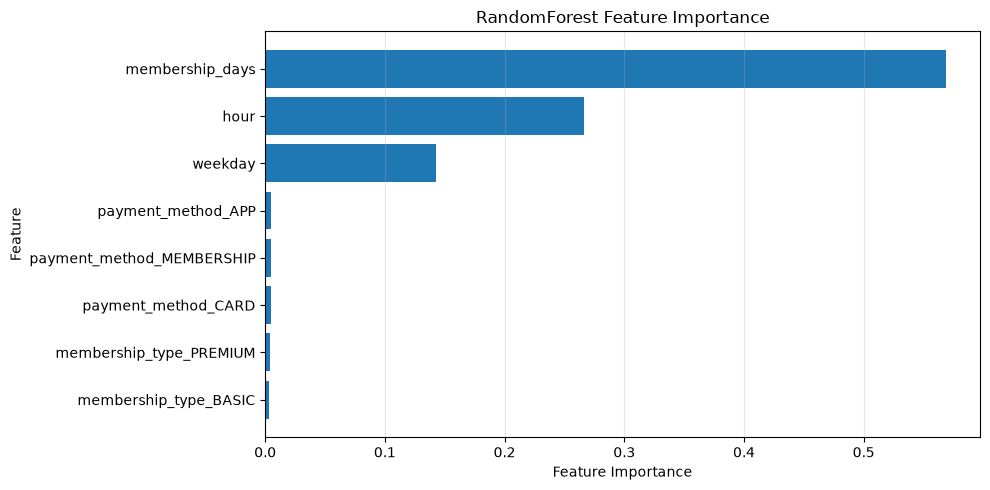

In [23]:
# STEP 9. 변수 중요도 분석

import pandas as pd
import matplotlib.pyplot as plt

# STEP 6에서 학습한 랜덤포레스트 모델
rf_model = models["RandomForest_balanced"]

# 변수 중요도 계산
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

# 중요도 높은 순으로 정렬
importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

print("=== STEP 9 변수 중요도 ===")
print(importance_df.to_string(index=False))

# 그래프
plt.figure(figsize=(10, 5))

plt.barh(
    importance_df["feature"],
    importance_df["importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("RandomForest Feature Importance")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()